# Davíð's notebook

#### Exploratory analysis of the data

##### Load and inspect

We load the features, expert votes, train/test split, and feature descriptions, then check that every table covers the same 17,089 EEG segments. The votes and split groups are combined into one table (`meta`) for the analysis below.

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

data_dir = "../HMSdata_prepared"
features = pd.read_csv(f"{data_dir}/features.csv")
labels = pd.read_csv(f"{data_dir}/label.csv")
split = pd.read_csv(f"{data_dir}/train_test.csv")
descriptions = pd.read_csv(f"{data_dir}/feature_descriptions.csv")

tables = {"features": features, "labels": labels, "split": split, "descriptions": descriptions}
for name, table in tables.items():
    print(name, table.shape)
    display(table.head(3))

features (17089, 96)


,segment_id,patient_id,eeg_logpow_delta1,eeg_logpow_delta2,eeg_logpow_theta,eeg_logpow_alpha,eeg_logpow_beta,eeg_relpow_delta1,eeg_relpow_delta2,eeg_relpow_theta,...,spect_reldelta_std,spect_reldelta_slope,spect_evo_peakfreq_range,spect_evo_logpow_range,spect_peakfreq_median,spect_entropy_median,spect_stability,spect_asym_delta,spect_asym_total,spect_nan_frac
0,1,42516,1.461893,1.540767,1.566393,1.018688,1.215860,0.207959,0.276346,0.228102,...,0.057239,0.002313,1.36,0.128195,2.15,0.816982,0.963119,0.217572,0.297412,0.0
1,2,30539,1.243672,1.309647,0.842975,0.277363,-0.449872,0.319113,0.468289,0.164293,...,0.039450,0.002434,2.15,0.108364,2.34,0.735160,0.751589,0.070416,0.064455,0.0
2,3,56885,2.570554,2.031281,1.343681,0.578681,0.168920,0.721561,0.214177,0.055476,...,0.035010,0.005553,0.39,0.525525,1.17,0.591299,0.982874,0.542108,0.532484,0.0


labels (17089, 10)


,segment_id,patient_id,seizure_vote,lpd_vote,gpd_vote,lrda_vote,grda_vote,other_vote,expert_consensus,num_votes
0,1,42516,3,0,0,0,0,0,Seizure,3
1,2,30539,0,0,5,0,1,5,GPD,11
2,3,56885,0,1,0,14,0,1,LRDA,16


split (17089, 4)


,segment_id,patient_id,num_votes,group
0,1,42516,3,excluded_low_votes
1,2,30539,11,train_pool
2,3,56885,16,train_pool


descriptions (94, 4)


,name,group,window,description
0,eeg_logpow_delta1,A1_spectral,c10,"log10 absolute power 0.5-2 Hz (µV²), median ov..."
1,eeg_logpow_delta2,A1_spectral,c10,"log10 absolute power 2-4 Hz (µV²), median over..."
2,eeg_logpow_theta,A1_spectral,c10,"log10 absolute power 4-8 Hz (µV²), median over..."


In [43]:
for name in ["features", "labels", "split"]:
    print(name, "unique ids:", tables[name]["segment_id"].is_unique)
print("same ids:", set(features["segment_id"]) == set(labels["segment_id"]) == set(split["segment_id"]))

# Take only the new column from split, so patient_id and num_votes aren't duplicated
meta = labels.merge(split[["segment_id", "group"]], on="segment_id", validate="one_to_one")
meta.shape

features unique ids: True
labels unique ids: True
split unique ids: True
same ids: True


(17089, 11)

##### Votes and classes

We look at how many experts labeled each segment, how often they agreed, and how common each class is in each split. This shows how much disagreement there is for active learning to work with, and whether train and test have similar class balance.

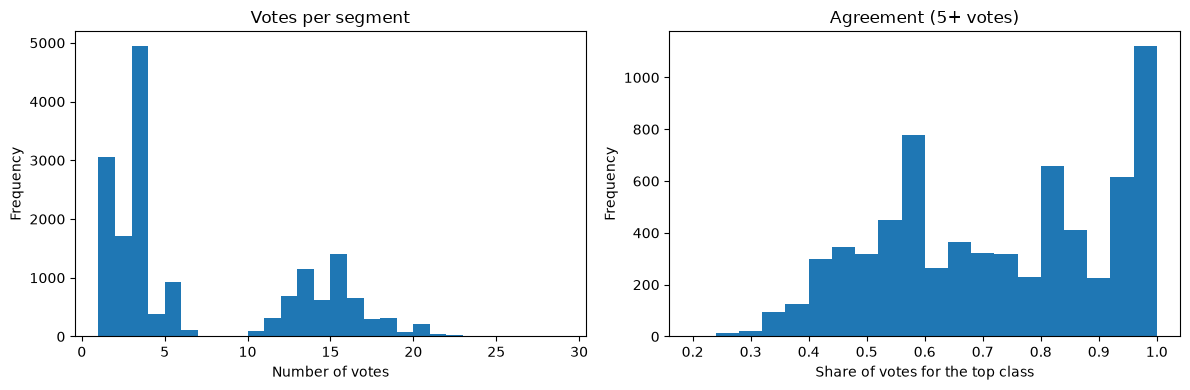

In [44]:
vote_cols = ["seizure_vote", "lpd_vote", "gpd_vote", "lrda_vote", "grda_vote", "other_vote"]
class_order = ["Seizure", "LPD", "GPD", "LRDA", "GRDA", "Other"]
group_order = ["train_pool", "excluded_low_votes", "test", "excluded_test_patient"]

soft_labels = meta[vote_cols].div(meta["num_votes"], axis=0)
meta["top_share"] = soft_labels.max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
meta["num_votes"].plot.hist(bins=range(1, 30), ax=axes[0], title="Votes per segment")
axes[0].set_xlabel("Number of votes")
meta.loc[meta["num_votes"] >= 5, "top_share"].plot.hist(bins=20, ax=axes[1], title="Agreement (5+ votes)")
axes[1].set_xlabel("Share of votes for the top class")
plt.tight_layout()
plt.show()

group,train_pool,excluded_low_votes,test,excluded_test_patient
expert_consensus,,,,
Seizure,663,1362,48,555
LPD,1063,974,214,356
GPD,666,795,156,195
LRDA,265,495,61,125
GRDA,352,1038,88,366
Other,2560,3244,588,860


group,train_pool,excluded_low_votes,test,excluded_test_patient
expert_consensus,,,,
Seizure,0.119,0.172,0.042,0.226
LPD,0.191,0.123,0.185,0.145
GPD,0.120,0.101,0.135,0.079
LRDA,0.048,0.063,0.053,0.051
GRDA,0.063,0.131,0.076,0.149
Other,0.460,0.410,0.509,0.350


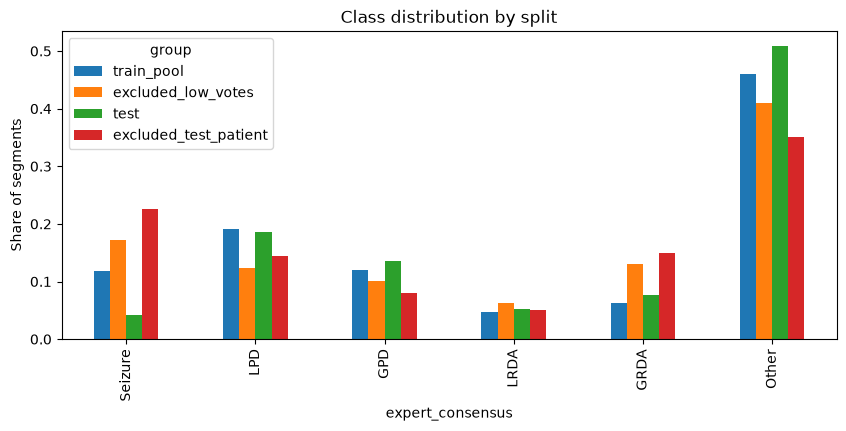

In [45]:
class_counts = pd.crosstab(meta["expert_consensus"], meta["group"]).loc[class_order, group_order]
class_shares = class_counts / class_counts.sum()
display(class_counts, class_shares.round(3))

class_shares.plot.bar(figsize=(10, 4), title="Class distribution by split", ylabel="Share of segments")
plt.show()

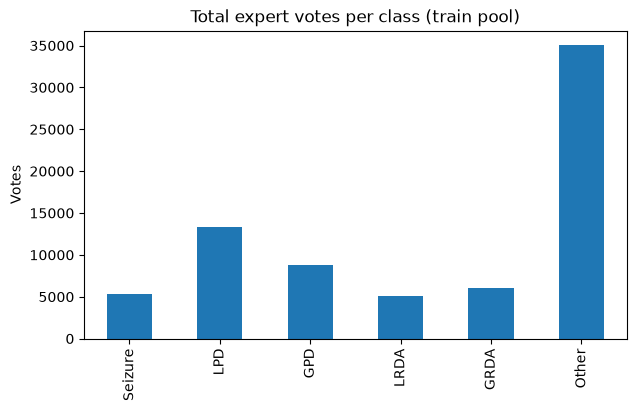

In [46]:
# Total expert votes per class in the training pool
total_votes = meta.loc[meta["group"] == "train_pool", vote_cols].sum()
total_votes.index = class_order

total_votes.plot.bar(figsize=(7, 4), title="Total expert votes per class (train pool)", ylabel="Votes")
plt.show()

#### Patients and splits

We summarize the segments, patients, and votes in each group and confirm that no patient appears in both train and test, which would inflate our results. We also check how unevenly segments are spread across patients.

,segments,patients,total_votes,median_votes
group,,,,
train_pool,5569,996,73587,14.0
excluded_low_votes,7908,1289,17558,3.0
test,1155,212,16952,15.0
excluded_test_patient,2457,352,6602,3.0


patients in both: 0


count    1950.0
mean        8.8
std        20.3
min         1.0
25%         2.0
50%         3.0
75%         5.0
max       270.0
dtype: float64

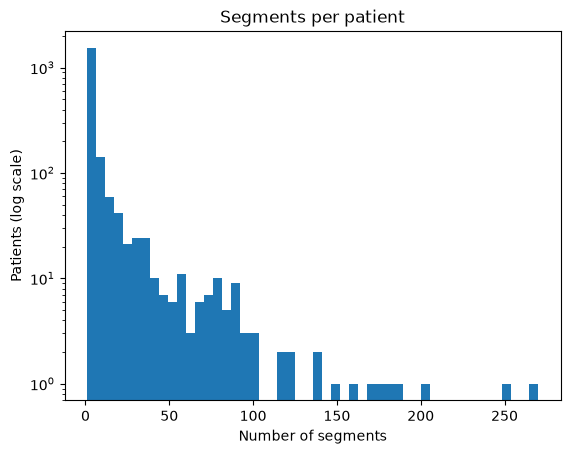

In [47]:
summary = (meta.groupby("group")
    .agg(segments=("segment_id", "size"), patients=("patient_id", "nunique"),
         total_votes=("num_votes", "sum"), median_votes=("num_votes", "median"))
    .loc[group_order])
display(summary)

test_patients = set(meta.loc[meta["group"].isin(["test", "excluded_test_patient"]), "patient_id"])
train_patients = set(meta.loc[meta["group"].isin(["train_pool", "excluded_low_votes"]), "patient_id"])
print("patients in both:", len(test_patients & train_patients))

segments_per_patient = meta.groupby("patient_id").size()
display(segments_per_patient.describe().round(1))
segments_per_patient.plot.hist(bins=50, log=True, title="Segments per patient")
plt.xlabel("Number of segments")
plt.ylabel("Patients (log scale)")
plt.show()

#### Features

We check how much data is missing per feature and how feature values differ between classes, using the training pool only. This guides the preprocessing and feature selection below.

features with missing values: 27 | highest: 0.144 %


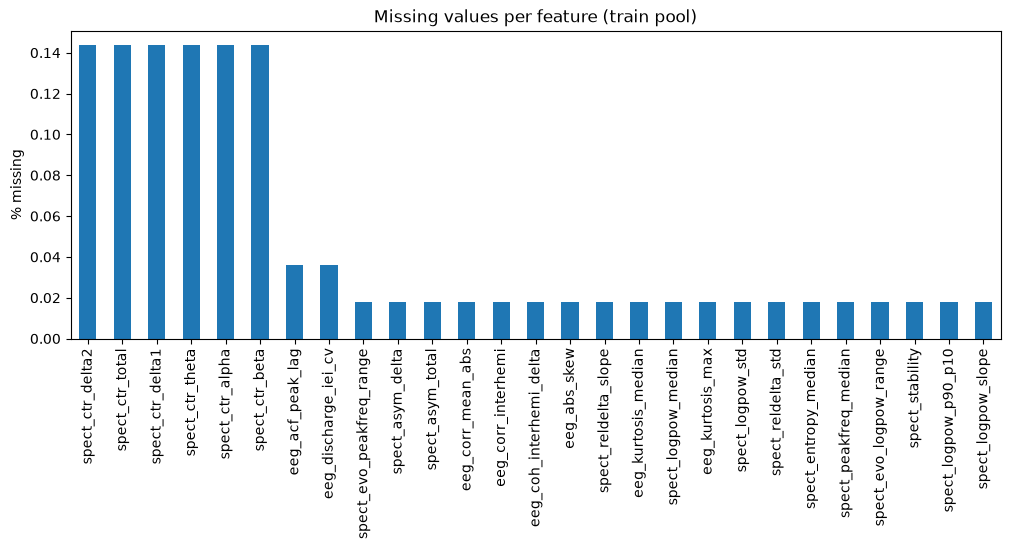

In [48]:
feature_cols = descriptions["name"].tolist()
train_features = features.merge(meta.loc[meta["group"] == "train_pool", ["segment_id", "expert_consensus"]],
                                on="segment_id", validate="one_to_one")

missing_pct = (train_features[feature_cols].isna().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
print("features with missing values:", len(missing_pct), "| highest:", round(missing_pct.max(), 3), "%")

missing_pct.plot.bar(figsize=(12, 4), title="Missing values per feature (train pool)", ylabel="% missing")
plt.show()

##### Feature values by class

We plot one feature from each feature group, with a separate curve per class. Curves that separate clearly suggest the feature helps distinguish those classes.

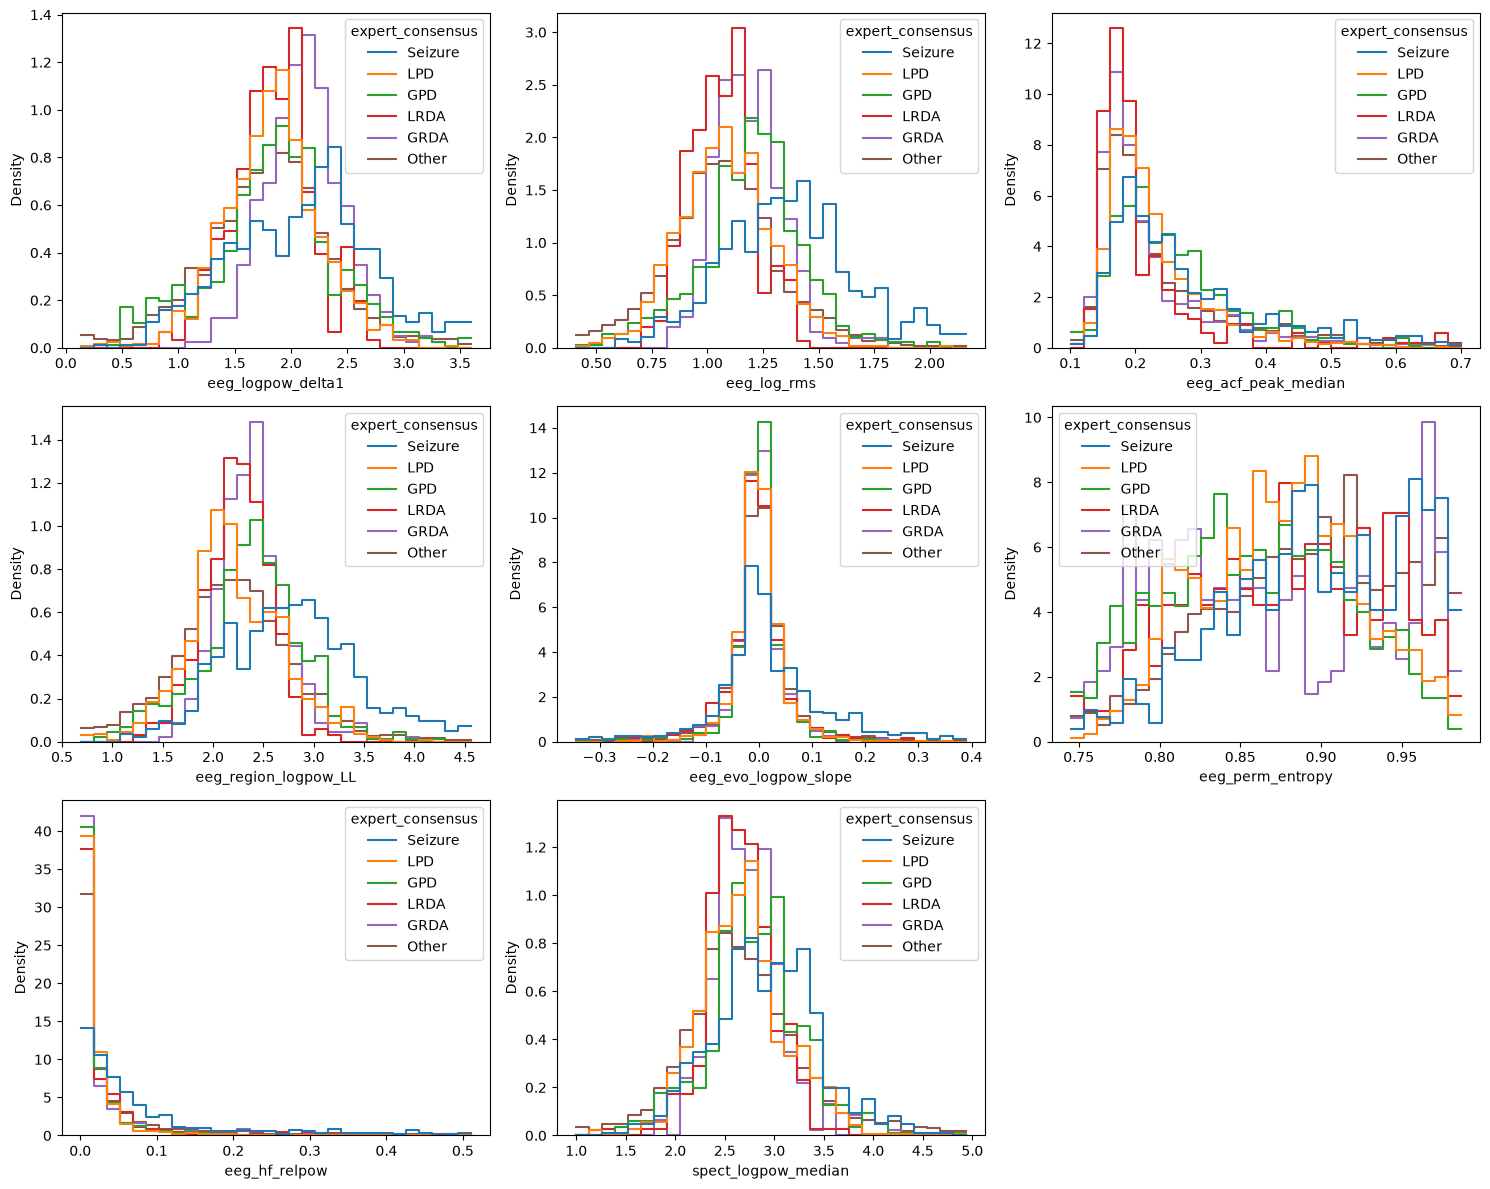

In [49]:
import numpy as np
import seaborn as sns

# One feature from each feature group, so every type of feature is represented
plot_features = descriptions.groupby("group")["name"].first().tolist()

n_cols = 3
n_rows = int(np.ceil(len(plot_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.ravel()

for ax, feature in zip(axes, plot_features):
    # Hide the most extreme 2% of values so the shapes are readable
    low, high = train_features[feature].quantile([0.01, 0.99])
    plot_data = train_features[train_features[feature].between(low, high)]

    # density + common_norm=False lets small classes be compared with large ones
    sns.histplot(data=plot_data, x=feature, hue="expert_consensus", hue_order=class_order,
                 stat="density", common_norm=False, element="step", fill=False, bins=30, ax=ax)

for ax in axes[len(plot_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

#### Split features into train and test

We separate the 94 features into the training pool and the test set using the split provided by Dr. Pale. All preprocessing below is learned from the training data only, so no test information leaks into the model.

In [30]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, StandardScaler

feature_cols = descriptions["name"].tolist()
data = features.merge(meta[["segment_id", "group"]], on="segment_id", validate="one_to_one")

train_data = data[data["group"] == "train_pool"]
test_data = data[data["group"] == "test"]

X_train = train_data[feature_cols]
X_test = test_data[feature_cols]
print(X_train.shape, X_test.shape)

(5569, 94) (1155, 94)


#### Impute missing values

A small number of feature values are missing, so we fill each one with that feature's median from the training set. The median is used because it is not distorted by extreme values.

In [50]:
imputer = SimpleImputer(strategy="median").set_output(transform="pandas")

X_train_imp = imputer.fit_transform(X_train)   # learns medians from train
X_test_imp = imputer.transform(X_test)         # reuses the train medians

print("missing:", X_train_imp.isna().sum().sum(), X_test_imp.isna().sum().sum())

missing: 0 0


#### Transform skewed features

Some features have a long tail of extreme values that can dominate a model. We apply a Yeo-Johnson transform, similar to a log transform but able to handle zeros and negative values, to features with |skew| > 2.

In [51]:
skewed_cols = X_train_imp.columns[X_train_imp.skew().abs() > 2].tolist()
power = PowerTransformer(method="yeo-johnson", standardize=False).set_output(transform="pandas")

X_train_pow = X_train_imp.copy()
X_test_pow = X_test_imp.copy()
X_train_pow[skewed_cols] = power.fit_transform(X_train_imp[skewed_cols])
X_test_pow[skewed_cols] = power.transform(X_test_imp[skewed_cols])

print("skewed before:", len(skewed_cols), "after:", (X_train_pow.skew().abs() > 2).sum())

skewed before: 39 after: 7


#### Standardize

We rescale every feature to mean 0 and standard deviation 1 using the training set's values. This puts features on a comparable scale, which matters especially for logistic regression.

In [53]:
scaler = StandardScaler().set_output(transform="pandas")

X_train_scaled = scaler.fit_transform(X_train_pow)
X_test_scaled = scaler.transform(X_test_pow)

X_train_scaled.describe().loc[["mean", "std"]].round(2)

,eeg_logpow_delta1,eeg_logpow_delta2,eeg_logpow_theta,eeg_logpow_alpha,eeg_logpow_beta,eeg_relpow_delta1,eeg_relpow_delta2,eeg_relpow_theta,eeg_relpow_alpha,eeg_relpow_beta,...,spect_reldelta_std,spect_reldelta_slope,spect_evo_peakfreq_range,spect_evo_logpow_range,spect_peakfreq_median,spect_entropy_median,spect_stability,spect_asym_delta,spect_asym_total,spect_nan_frac
mean,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,...,-0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


#### Drop near-constant features

Features with the same value in at least 95% of training segments carry almost no information, so we remove them. This takes us from 94 to 92 features.

In [54]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold

# Share of rows taken by each feature's most common value
top_share = X_train_scaled.apply(lambda col: col.value_counts(normalize=True).iloc[0])
near_constant = top_share[top_share >= 0.95].index.tolist()

candidates = [col for col in feature_cols if col not in near_constant]
print("dropped:", near_constant)
print("left:", len(candidates))

dropped: ['eeg_n_flat_channels', 'eeg_nan_frac']
left: 92


#### Drop highly correlated features

When two features are nearly identical (|r| > 0.95), we keep only one because the other adds little new information. This takes us from 92 to 84 features.

In [55]:
corr = X_train_scaled[candidates].corr().abs()

kept = []
for col in candidates:
    # Keep a feature only if it isn't too similar to one we already kept
    if (corr.loc[col, kept] <= 0.95).all():
        kept.append(col)

print("left:", len(kept))

left: 84


#### Rank by random forest importance

The earlier filters do not use the labels, so we train a random forest on the expert vote shares to rank features by how useful they are. Importance is averaged over 5 folds, keeping each patient within a single fold.

In [37]:
train_meta = meta.set_index("segment_id").loc[train_data["segment_id"]]
y_train = train_meta[vote_cols].div(train_meta["num_votes"], axis=0).to_numpy()
groups = train_data["patient_id"].to_numpy()

cv = GroupKFold(n_splits=5)
fold_importances = []

for train_idx, _ in cv.split(X_train_scaled[kept], y_train, groups):
    forest = RandomForestRegressor(n_estimators=200, max_features="sqrt",
                                   min_samples_leaf=5, n_jobs=-1, random_state=42)
    forest.fit(X_train_scaled[kept].iloc[train_idx], y_train[train_idx])
    fold_importances.append(forest.feature_importances_)

importance = pd.Series(np.mean(fold_importances, axis=0), index=kept).sort_values(ascending=False)
importance.head(10)

spect_asym_delta             0.044010
eeg_discharge_rate_median    0.039302
eeg_logpow_theta             0.030368
eeg_relpow_delta1            0.027267
eeg_logpow_alpha             0.027115
eeg_discharge_rate_max       0.025824
eeg_relpow_delta2            0.025526
eeg_logpow_delta2            0.022911
eeg_kurtosis_median          0.022861
eeg_asym_lat_theta           0.021808
dtype: float64

#### Keeping the best features

We compare different feature counts using cross-validated KL divergence on the training data, where lower is better. Performance levels off between 30 and 49 features, so we keep the top 30 as the smallest set on that plateau.

In [39]:
from scipy.special import rel_entr

def kl_divergence(y_true, y_pred, eps=1e-7):
    y_pred = np.clip(y_pred, eps, 1)                    # avoids log(0)
    y_pred = y_pred / y_pred.sum(axis=1, keepdims=True)  # sums to 1 again
    return rel_entr(y_true, y_pred).sum(axis=1).mean()

def make_forest():
    return RandomForestRegressor(n_estimators=200, max_features="sqrt",
                                 min_samples_leaf=5, n_jobs=-1, random_state=42)

feature_counts = [10, 20, 30, 40, 49, 60, 84]
X_kept = X_train_scaled[kept]
rows = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_kept, y_train, groups)):
    X_fit, X_val = X_kept.iloc[train_idx], X_kept.iloc[val_idx]
    y_fit, y_val = y_train[train_idx], y_train[val_idx]

    # Rank using this fold's training data only, so validation stays unseen
    ranking = pd.Series(make_forest().fit(X_fit, y_fit).feature_importances_,
                        index=kept).sort_values(ascending=False)

    for k in feature_counts:
        top_k = ranking.head(k).index
        model = make_forest().fit(X_fit[top_k], y_fit)
        kl = kl_divergence(y_val, model.predict(X_val[top_k]))
        rows.append({"fold": fold, "n_features": k, "kl": kl})

results = pd.DataFrame(rows)
summary = results.groupby("n_features")["kl"].agg(["mean", "std"])
summary["se"] = summary["std"] / np.sqrt(cv.get_n_splits())
summary.round(4)

,mean,std,se
n_features,,,
10,0.5606,0.0192,0.0086
20,0.5160,0.0240,0.0108
30,0.5093,0.0275,0.0123
40,0.5095,0.0261,0.0117
49,0.5099,0.0276,0.0123
60,0.5131,0.0265,0.0119
84,0.5160,0.0266,0.0119


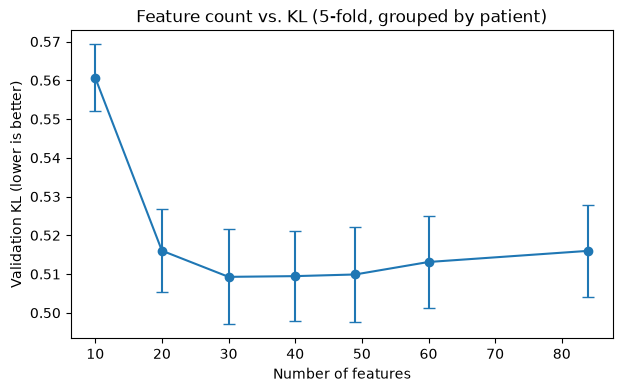

In [40]:
plt.figure(figsize=(7, 4))
plt.errorbar(summary.index, summary["mean"], yerr=summary["se"], marker="o", capsize=4)
plt.xlabel("Number of features")
plt.ylabel("Validation KL (lower is better)")
plt.title("Feature count vs. KL (5-fold, grouped by patient)")
plt.show()

In [41]:
n_features = 30
selected_features = importance.head(n_features).index.tolist()

X_train_final = X_train_scaled[selected_features]
X_test_final = X_test_scaled[selected_features]
print(X_train_final.shape, X_test_final.shape)

(5569, 30) (1155, 30)
